# Tester for 1D Regression with Neural Network

In [1]:
import numpy as np
import torch
from torch.distributions import Normal
import matplotlib.pyplot as plt
import time


# Print versions
print(f"torch version: {torch.__version__}")

# Print Information on GPU
# Check GPU availability
if torch.cuda.is_available():
  print(f"GPU is available: {torch.cuda.get_device_name(0)}")
else:
  print("GPU is not available.")

torch version: 2.5.1
GPU is not available.


## DGP

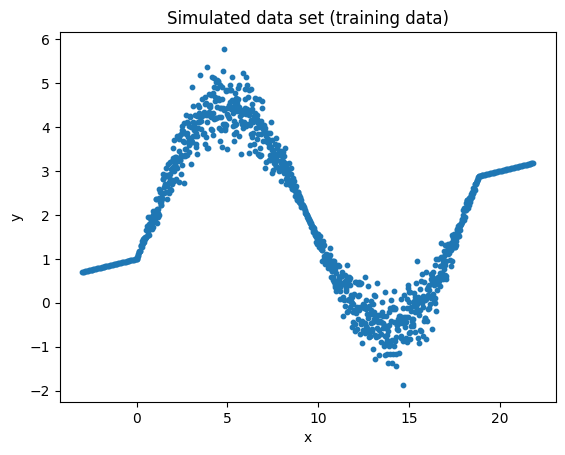

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def dgp_1(n):
    np.random.seed(42)
    N = 1000 # number of data points
    x_train = np.random.uniform(-10, 10, (N, 1)).astype(np.float32)
    y_train = (2 * x_train + np.random.normal(0, np.abs(x_train) + 1, (N, 1))).astype(np.float32)
    return x_train.reshape(1,-1), y_train.reshape(1,-1)


def dgp_2(n):
    np.random.seed(32)
    x = np.linspace(0,1*2*np.pi,n)
    y1 = 3*np.sin(x)
    y1 = np.concatenate((np.zeros(60), y1+np.random.normal(0,0.15*np.abs(y1),n),np.zeros(60)))
    x=np.concatenate((np.linspace(-3,0,60),np.linspace(0,3*2*np.pi,n),np.linspace(3*2*np.pi,3*2*np.pi+3,60)))
    y2 = 0.1*x+1
    y=y1+y2
    return x.reshape(-1,1),y.reshape(-1,1)

dgp = dgp_2

x_train, y_train = dgp(1000)
plt.scatter(x_train, y_train, s=10)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Simulated data set (training data)')

# Predict the distribution
x_test = np.linspace(-10, 30, 100).reshape(-1, 1)

# -------------------------------------------------------------------------
# 
#  STOP - PLEASE DISCUSS THE PLOT ABOVE BEFORE SCROLLING DOWN
#
# -------------------------------------------------------------------------
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30





























###

```
# -------------------------------------------------------------------------
# 
#  STOP - PLEASE DISCUSS THE PLOT ABOVE BEFORE SCROLLING DOWN
#
# -------------------------------------------------------------------------











```

## Definition of the network

What model would you use for this task?

```
# -------------------------------------------------------------------------
# 
#  STOP 
#
# -------------------------------------------------------------------------






```

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim

class regression_model(nn.Module):
    def __init__(self):
        super(regression_model, self).__init__()
        # Standard layers with Tanh activation 
        self.network = nn.Sequential(
            nn.Linear(1, 20),
            nn.Tanh(),
            nn.Linear(20, 50),
            nn.Tanh(),
            nn.Linear(50, 20),
            nn.Tanh(),
            nn.Linear(20, 2)  
        )

    def forward(self, x):
        return self.network(x)

# Initialization
model = regression_model()

Explain the model
- Why do you have 2 outputs, what do they mean?


## Loss Function 
What loss function would you use for this task?

```
# -------------------------------------------------------------------------
# 
#  STOP - PLEASE DISCUSS THE ABOVE BEFORE SCROLLING DOWN
#
# -------------------------------------------------------------------------


In [4]:
# The "Statistical" Loss Function
# This replaces MSE to allow the model to learn non-constant variance
def gaussian_nll_loss(output, target):
    """
    output[:, 0] -> predicted mean (mu)
    output[:, 1] -> predicted log_variance (log_var)
    """
    mu = output[:, 0].unsqueeze(1)
    log_var = output[:, 1].unsqueeze(1)
    
    # Precision = 1 / variance
    precision  = torch.exp(-log_var)
    
    # NLL formula: 
    return torch.mean(0.5 * ( (target - mu)**2)*precision + log_var)

### What is the following code doing?

In [5]:
import torch
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_history = []
epochs = 5000
x_train = torch.tensor(x_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
for epoch in range(epochs):
    model.train()
    
    # 
    predictions = model(x_train)
    
    # Calculate Gaussian NLL Loss
    loss = gaussian_nll_loss(predictions, y_train)
    
    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Record history
    loss_history.append(loss.item())
    
    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d} | Loss: {loss.item():.4f}")

Epoch    0 | Loss: 3.6809
Epoch  200 | Loss: -0.1482
Epoch  400 | Loss: -1.2314
Epoch  600 | Loss: -1.9853
Epoch  800 | Loss: -2.3671
Epoch 1000 | Loss: -2.6666
Epoch 1200 | Loss: -2.8357
Epoch 1400 | Loss: -2.9502
Epoch 1600 | Loss: -3.0749
Epoch 1800 | Loss: -3.1699
Epoch 2000 | Loss: -3.2282
Epoch 2200 | Loss: -3.2647
Epoch 2400 | Loss: -3.2542
Epoch 2600 | Loss: -3.3297
Epoch 2800 | Loss: -3.3201
Epoch 3000 | Loss: -3.3679
Epoch 3200 | Loss: -3.3535
Epoch 3400 | Loss: -3.1279
Epoch 3600 | Loss: -3.3899
Epoch 3800 | Loss: -3.3504
Epoch 4000 | Loss: -3.4000
Epoch 4200 | Loss: -3.3509
Epoch 4400 | Loss: -3.4001
Epoch 4600 | Loss: -3.4298
Epoch 4800 | Loss: -3.4143


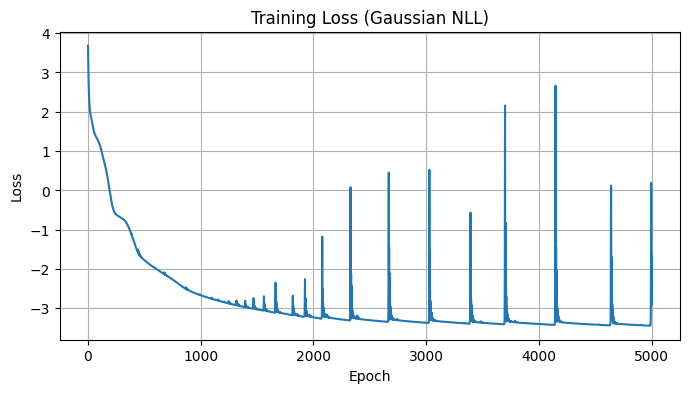

In [6]:
# 3. Visualization of the Training Process
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Training Loss (Gaussian NLL)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

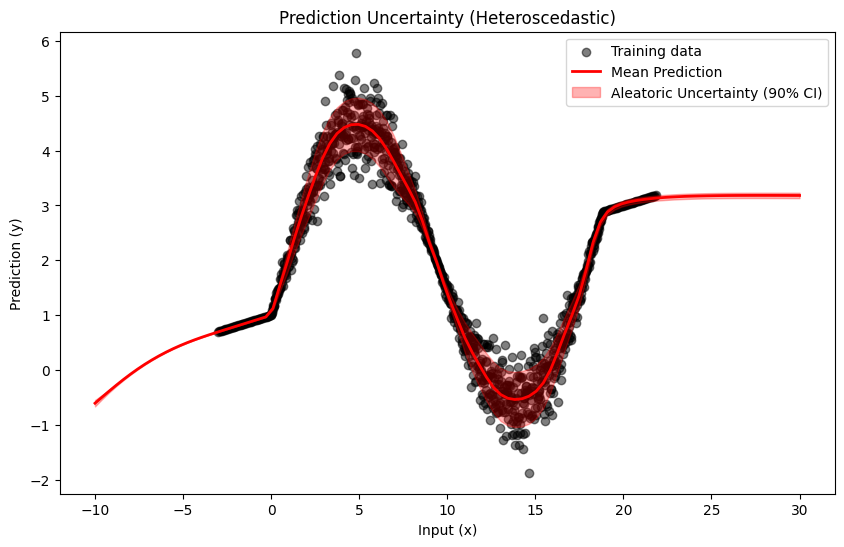

In [7]:
import torch.distributions as dist_util
import matplotlib.pyplot as plt

# 1. Prediction on the test range
# Predict the distribution
x_test = torch.tensor(np.linspace(-10, 30, 100).reshape(-1, 1), dtype=torch.float32)
model.eval()
with torch.no_grad():
    output = model(x_test)
    mu_pred = output[:, 0]
    log_var_pred = output[:, 1]
    # Convert log(var) to std: sigma = exp(0.5 * log_var)
    std_pred = torch.exp(0.5 * log_var_pred)

# 2. Define the Gaussian Distribution object
# This allows us to use .icdf (Inverse Cumulative Distribution Function)
prediction_dist = dist_util.Normal(mu_pred, std_pred)

# 3. Calculate Quantiles for the Aleatoric Uncertainty
quantile_5 = prediction_dist.icdf(torch.tensor(0.05)).cpu().detach().numpy()
quantile_95 = prediction_dist.icdf(torch.tensor(0.95)).cpu().detach().numpy()
mean = prediction_dist.mean.cpu().detach().numpy().squeeze()

# 4. Visualisierung
plt.figure(figsize=(10, 6))
plt.scatter(x_train.numpy(), y_train.numpy(), color="black", alpha=0.5, label="Training data")
plt.plot(x_test.numpy(), mean, color="red", lw=2, label="Mean Prediction")

plt.fill_between(
    x_test.numpy().ravel(),
    quantile_5.squeeze(),  # 5%-Quantile
    quantile_95.squeeze(),  # 95%-Quantile
    color="red",
    alpha=0.3,
    label="Aleatoric Uncertainty (90% CI)"
)

plt.legend()
plt.xlabel("Input (x)")
plt.ylabel("Prediction (y)")
plt.title("Prediction Uncertainty (Heteroscedastic)")
plt.show()

### Lock at the graph

The model is mathematically certain that there is little noise at \(x=30\), even though it has never seen data there. Why is it 'lying' to us, and how would we change the architecture so the red area actually gets wider in regions without data?